In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from cmdstanpy import CmdStanModel
from scipy import stats
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Bayesian AR

In [2]:
# Load data
unrate = pd.read_csv('data/UNRATE.csv', index_col='observation_date', parse_dates=True)
unrate = unrate.loc[:'2019']
y_full = unrate['UNRATE'].values

In [3]:
p = 12 # lag length
X = sm.tsa.tsatools.lagmat(y_full, maxlag=p, trim='both') # lag matrix

# Data for Stan
std_y = y_full.std()
stan_data = {
    'T': X.shape[0],
    'p': p,
    'y': y_full[p:],
    'X': X,
    'lambda': 0.2,
    'scale_sigma': std_y,
    'scale_c': 100*std_y,
}

# Compile and sample
model = CmdStanModel(stan_file='slides12_ar.stan')
fit = model.sample(data=stan_data, seed=31150, chains=4,
                   iter_warmup=1000, iter_sampling=1000, show_progress=True)

print(fit.summary())

14:02:55 - cmdstanpy - INFO - CmdStan start processing


chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

14:03:01 - cmdstanpy - INFO - CmdStan done processing.
14:03:01 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_lpdf: Scale parameter is 0, but must be positive! (in 'slides12_ar.stan', line 32, column 2 to column 31)
Consider re-running with show_console=True if the above output is unclear!



              Mean      MCSE    StdDev       MAD           5%          50%  \
lp__   1010.280000  0.063370  2.759430  2.557710  1005.270000  1010.630000   
c         0.089636  0.000391  0.025454  0.025671     0.047837     0.089861   
a[1]      1.012370  0.000595  0.032229  0.032269     0.960301     1.011730   
a[2]      0.172059  0.000791  0.042703  0.042244     0.099819     0.172488   
a[3]     -0.045320  0.000651  0.037394  0.037117    -0.106699    -0.044841   
a[4]     -0.046709  0.000604  0.033100  0.033077    -0.101172    -0.047124   
a[5]     -0.022017  0.000501  0.029876  0.030123    -0.070184    -0.022069   
a[6]     -0.055230  0.000435  0.026066  0.026362    -0.097376    -0.055347   
a[7]     -0.029408  0.000372  0.023062  0.023177    -0.066451    -0.029906   
a[8]     -0.006612  0.000336  0.020786  0.020602    -0.040138    -0.006695   
a[9]     -0.006951  0.000293  0.019024  0.019120    -0.038650    -0.006727   
a[10]    -0.006285  0.000267  0.016710  0.016886    -0.033778  

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


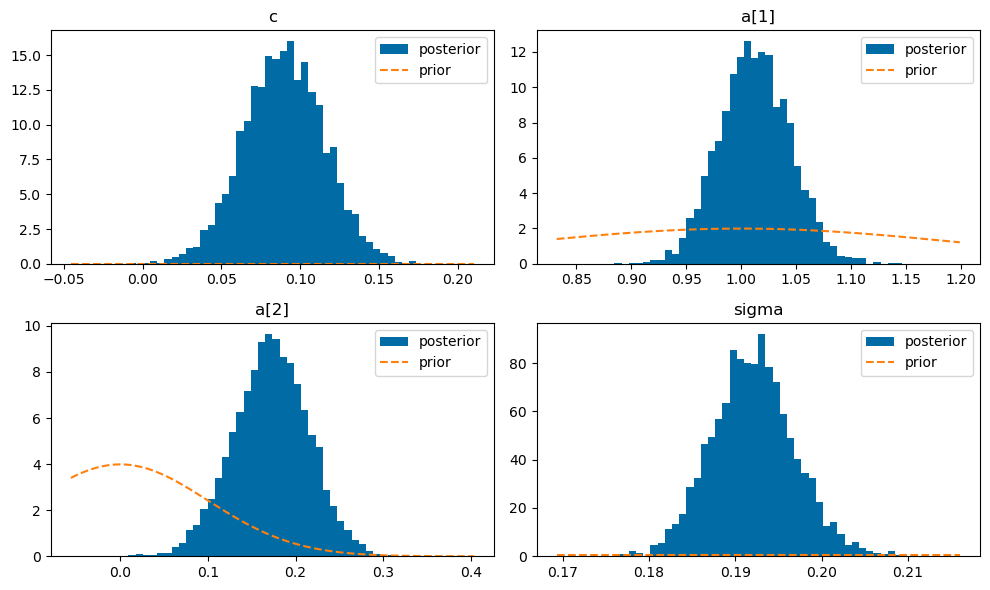

In [4]:
# Posterior vs. prior
params = ['c', 'a[1]', 'a[2]', 'sigma']
prior_pdf = {
    'c':     lambda x: stats.norm.pdf(x, 0, stan_data['scale_c']),
    'a[1]':  lambda x: stats.norm.pdf(x, 1, stan_data['lambda'] / 1),
    'a[2]':  lambda x: stats.norm.pdf(x, 0, stan_data['lambda'] / 2),
    'sigma': lambda x: 2 * stats.cauchy.pdf(x, 0, stan_data['scale_sigma']) * (x >= 0),
}

draws = fit.draws_pd()

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, name in zip(axes.flat, params):
    draws_p = draws[name].values
    lo, hi = draws_p.min(), draws_p.max()
    pad = 0.2 * (hi - lo)
    grid = np.linspace(lo - pad, hi + pad, 400)
    ax.hist(draws_p, bins=40, density=True, label='posterior')
    ax.plot(grid, prior_pdf[name](grid), '--', label='prior')
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
fig.savefig('output/bayes_ar_posterior.eps')
plt.show()

In [5]:
# Posterior quantiles
print(np.quantile(draws['a[1]'].values, [0.025, 0.05, 0.95, 0.975]))

[0.95111886 0.96030143 1.06518581 1.07486885]


In [6]:
print(fit.diagnose())

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Rank-normalized split effective sample size satisfactory for all parameters.

Rank-normalized split R-hat values satisfactory for all parameters.

Processing complete, no problems detected.



The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


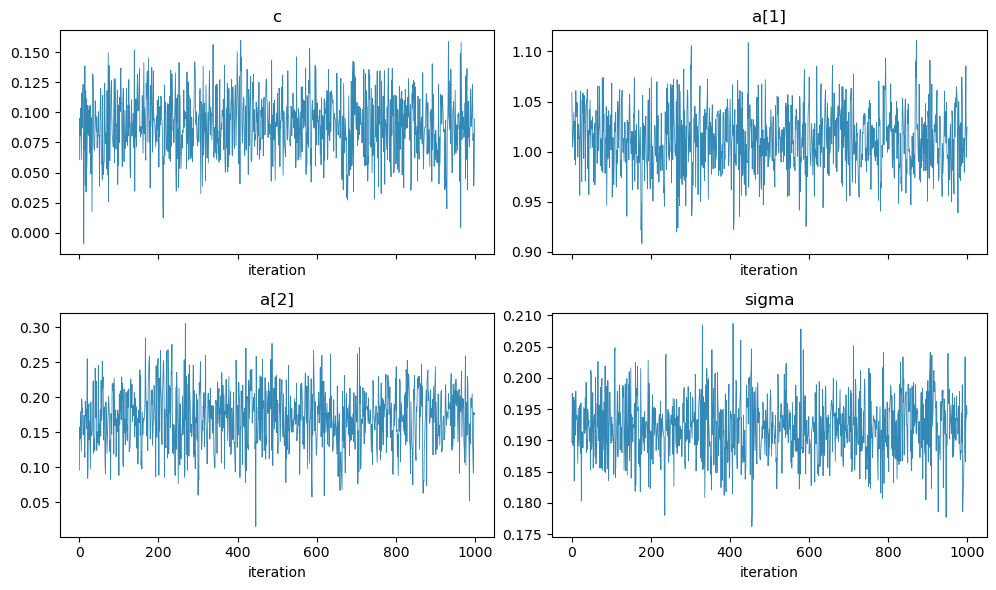

In [7]:
# Trace plots
draws_arr = fit.draws(concat_chains=False)  # (iterations, chains, parameters)
var_names = fit.column_names
plot_chain = 0 # plot the first chain

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, name in zip(axes.flat, params):
    j = var_names.index(name)
    ax.plot(draws_arr[:, plot_chain, j], lw=0.6, alpha=0.8)
    ax.set_title(name)
    ax.set_xlabel('iteration')
plt.tight_layout()
fig.savefig('output/bayes_ar_trace.eps')
plt.show()